In [87]:
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt 
import pandas as pd 

In [88]:
df = pd.read_csv('Student Social Media And Mental Health Impact.csv')

In [89]:
print(df.shape)
print(df.info())
print(df.describe())

(5000, 13)
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      5000 non-null   int64  
 1   Gender                   5000 non-null   str    
 2   Country                  5000 non-null   str    
 3   Academic_Level           5000 non-null   str    
 4   Most_Used_Platform       5000 non-null   str    
 5   Purpose_Of_Use           5000 non-null   str    
 6   Avg_Daily_Usage_Hours    5000 non-null   float64
 7   Daily_Unlocks            5000 non-null   int64  
 8   Study_Hours              5000 non-null   float64
 9   Physical_Activity_Hours  5000 non-null   float64
 10  Sleep_Hours_Per_Night    5000 non-null   float64
 11  Stress_Level             5000 non-null   str    
 12  Mental_Health_Score      5000 non-null   float64
dtypes: float64(5), int64(2), str(6)
memory usage: 736.5 KB
None
              Age 

In [90]:
df.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


In [91]:
df.duplicated().sum()

np.int64(2)

# EDA 

<Axes: xlabel='Mental_Health_Score', ylabel='Count'>

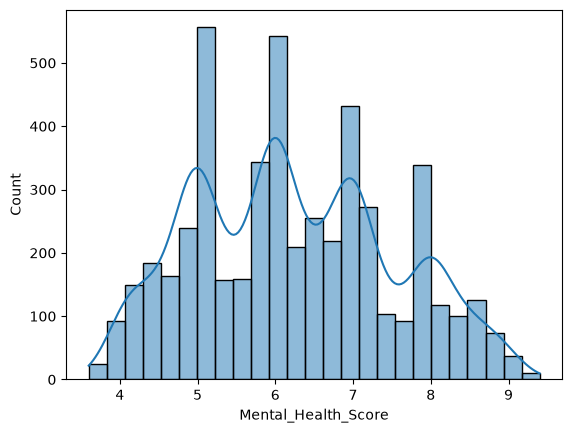

In [92]:
sns.histplot(df['Mental_Health_Score'],kde=True)

<Axes: >

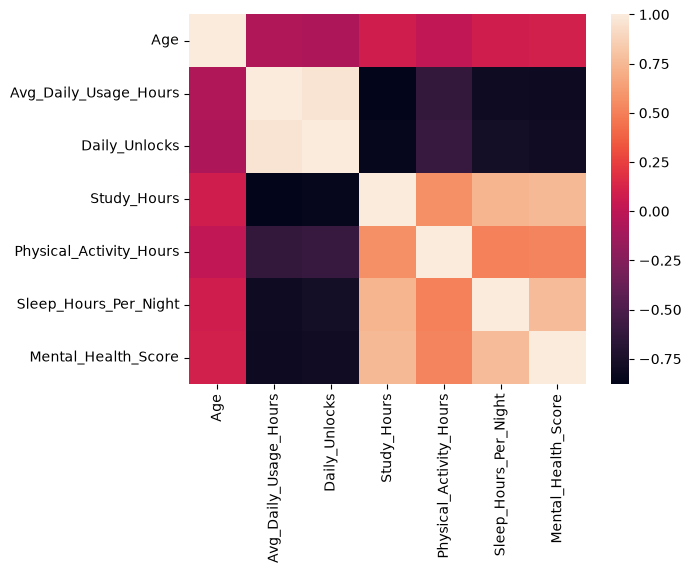

In [93]:
# co-relation - apply only in numeric columns 
sns.heatmap(df.corr(numeric_only=True))

In [94]:
df['Stress_Level'].unique()

<ArrowStringArray>
['Medium', 'Low', 'Very High', 'High']
Length: 4, dtype: str

<Axes: xlabel='Stress_Level', ylabel='Mental_Health_Score'>

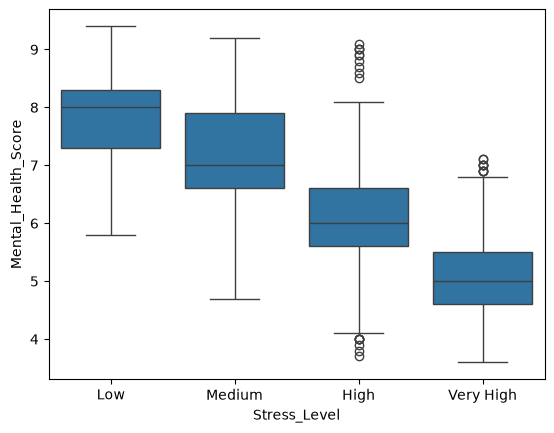

In [95]:
# category feature co-relation
order = [ 'Low', 'Medium', 'High','Very High']
sns.boxplot(data= df , x=df['Stress_Level'],y=df['Mental_Health_Score'],order=order)

<Axes: xlabel='Avg_Daily_Usage_Hours', ylabel='Mental_Health_Score'>

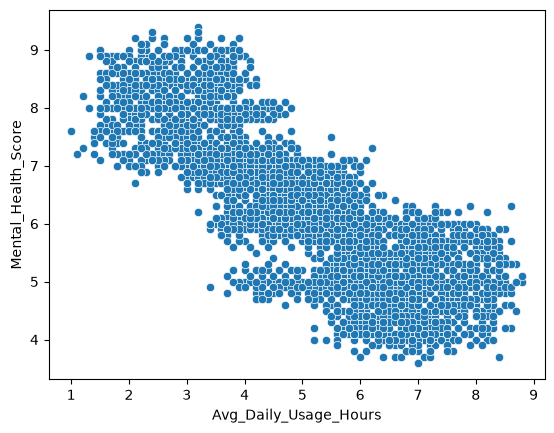

In [96]:
sns.scatterplot(data=df,x=df['Avg_Daily_Usage_Hours'],y=df['Mental_Health_Score'])

In [97]:
df['Most_Used_Platform'].unique()

<ArrowStringArray>
[ 'Facebook',  'LinkedIn', 'Instagram',  'Snapchat',   'Twitter',   'YouTube',
    'TikTok',      'LINE', 'KakaoTalk', 'VKontakte',  'WhatsApp',    'WeChat']
Length: 12, dtype: str

In [98]:
df['Most_Used_Platform'].value_counts().index

Index(['Instagram', 'TikTok', 'Facebook', 'LinkedIn', 'YouTube', 'Twitter',
       'Snapchat', 'WhatsApp', 'LINE', 'VKontakte', 'KakaoTalk', 'WeChat'],
      dtype='str', name='Most_Used_Platform')

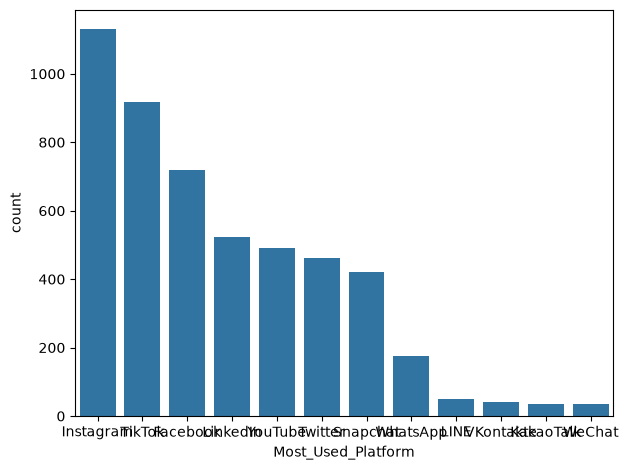

In [99]:
sns.countplot(data=df , x=df['Most_Used_Platform'],order=df['Most_Used_Platform'].value_counts().index)
plt.tight_layout()

In [100]:
# Checking outlier
numuric_feature = df.select_dtypes(include='number')

In [101]:
numuric_feature

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
0,21,4.0,134,4.5,2.2,6.7,6.8
1,23,1.6,73,7.0,2.4,8.6,7.6
2,22,4.6,166,4.0,1.8,6.7,7.0
3,18,7.0,220,1.0,1.7,5.4,5.3
4,24,7.5,237,1.0,1.1,5.0,4.4
...,...,...,...,...,...,...,...
4995,18,1.9,89,6.1,2.2,7.9,7.9
4996,18,6.6,216,2.3,1.8,6.0,4.7
4997,19,3.8,151,5.4,1.4,7.5,7.0
4998,18,3.8,119,4.0,1.5,6.4,6.7


In [102]:
Q1 = numuric_feature.quantile(0.25)
Q3 = numuric_feature.quantile(0.75)
IQR = Q3-Q1

lower_bound = Q1 - 1.5*IQR
upper_bound = Q3 + 1.5*IQR

outliers = (numuric_feature < lower_bound) | (numuric_feature > upper_bound)
print(outliers.sum())

Age                         0
Avg_Daily_Usage_Hours       0
Daily_Unlocks               0
Study_Hours                 2
Physical_Activity_Hours    22
Sleep_Hours_Per_Night       0
Mental_Health_Score         0
dtype: int64


#too small outliers so keep it 

# DATA CLEANING 

In [103]:
# 1. drop duplicates 
df.duplicated().sum()

np.int64(2)

In [104]:
df = df.drop_duplicates()

In [105]:
df.duplicated().sum()

np.int64(0)

In [106]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000
mean,20.822129,5.078491,171.455582,3.008403,1.750760,6.634654,6.231152
std,1.736774,1.654097,42.859829,1.636831,0.668406,1.221561,1.278476
min,18.000000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.000000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.000000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.000000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.000000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


# See in the data Physical_Activity_Hours feature have mean value less the 0 this is not possible 

In [107]:
# converting and un-realistic value to realistic value 
df['Physical_Activity_Hours'] = df['Physical_Activity_Hours'].clip(lower=0)

In [108]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000
mean,20.822129,5.078491,171.455582,3.008403,1.751160,6.634654,6.231152
std,1.736774,1.654097,42.859829,1.636831,0.667282,1.221561,1.278476
min,18.000000,1.000000,62.000000,0.300000,0.000000,3.600000,3.600000
25%,19.000000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.000000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.000000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.000000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


# SKEWNESS

In [109]:
numuric_feature.skew()

Age                        0.155325
Avg_Daily_Usage_Hours      0.005606
Daily_Unlocks              0.002351
Study_Hours                0.435819
Physical_Activity_Hours    0.039971
Sleep_Hours_Per_Night      0.124050
Mental_Health_Score        0.206567
dtype: float64

# if the value near the zero then centralized 

# if value is negative then left skewed 

# value is positive then right skewed 

# FEATURE ENGINEERING 

In [110]:
df['Country'].value_counts()

Country
Other         1879
India          389
USA            354
Canada         230
Australia      198
              ... 
Montenegro       1
Bosnia           1
Kuwait           1
Yemen            1
Syria            1
Name: count, Length: 111, dtype: int64

In [111]:
# top 10 countries
top_contries = df['Country'].value_counts().index[:10].tolist()

In [112]:
def group_country(country): 
    if country in top_contries: 
        return country
    else : 
        return "Country"


In [113]:
df['Grouped_contry'] = df['Country'].apply(group_country)

In [114]:
df['Grouped_contry'].value_counts()

Grouped_contry
Other        1879
Country      1352
India         389
USA           354
Canada        230
Australia     198
UK            185
Germany       136
Mexico         94
Turkey         94
France         87
Name: count, dtype: int64

# ENCODING STARTEGY


''' Before we jump into code, let's decide how each categorical column should be encoded — this decision matters more than the code itself.

Stress_Level → Ordinal Encoding. Its categories have a real, meaningful order: Low < Medium < High < Very High. We already saw in EDA (section 4.3) that the score drops step by step as stress increases — encoding it as 0, 1, 2, 3 preserves that order for the model.

Gender, Academic_Level, Most_Used_Platform, Purpose_Of_Use, Country_Grouped → One-Hot Encoding. These categories have no natural order — "Instagram" isn't "greater than" "LinkedIn". One-hot encoding creates a separate 0/1 column per category so the model doesn't accidentally assume a false ranking.

We'll implement both of these inside a single ColumnTransformer in the next step, rather than column by column — that keeps preprocessing consistent and reusable.'''

In [115]:
# fix skew value
skew_col = ['Study_Hours']

# numeric feature  
other_numeric_col = ['Age', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks','Physical_Activity_Hours', 'Sleep_Hours_Per_Night']

# to maintain order use  OrdinalEncoder not labelencoding
ordinal_col = ['Stress_Level']

# one hot encoding 
normal_col = [ 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Grouped_contry']

# all fetaure
fetaure_col = skew_col + other_numeric_col + ordinal_col + normal_col

# SPLITTING 

In [116]:
from sklearn.model_selection import train_test_split
x = df[fetaure_col]
y = df['Mental_Health_Score']
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.30, random_state=42)

# BUILDING PIPELINE 

In [117]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer , StandardScaler, OrdinalEncoder,OneHotEncoder
from sklearn.compose import ColumnTransformer
# 1. fix skew value
skew_pipeline = Pipeline(steps=[
    ('log_transformer',FunctionTransformer(np.log1p)),
    ('Scaler',StandardScaler())
])

# 2. numeric feature 
other_numeric_col_pipeline = Pipeline(steps=[
    ('Scaler',StandardScaler())
])

# 3. ordinal feature 
ordinal_col_pipline = Pipeline(steps=[
    ('encode',OrdinalEncoder(categories=[['Low','Medium','High','Very High']]))
])

# 4. normal feature 
normal_col_pipeline = Pipeline(steps=[
    ('encode',OneHotEncoder(handle_unknown='ignore'))
])
# (pipeline , feature)
preprocessor = ColumnTransformer(transformers=[
    ('Skewed_pipeline',skew_pipeline,skew_col), 
    ('plain_numeric',other_numeric_col_pipeline,other_numeric_col), 
    ('ordinal_pipeline',ordinal_col_pipline,ordinal_col), 
    ('normal_pipeline',normal_col_pipeline,normal_col)
])

In [118]:
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Skewed_pipeline', ...), ('plain_numeric', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_

# BUILDING MODEL

# 1. base line model 

In [119]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error,mean_squared_error

lr_pipeline = Pipeline(steps=[
    ('preprocessor',preprocessor), 
    ('regression',LinearRegression())
])

lr_pipeline.fit(X_train,y_train)
lr_pred = lr_pipeline.predict(X_test)
lr_pred_train = lr_pipeline.predict(X_train)

lr_r2_testing = r2_score(y_test,lr_pred)
lr_r2_training = r2_score(y_train,lr_pred_train)
lr_mae = mean_absolute_error(y_test,lr_pred)

print(f"Accuracy of testing : {lr_r2_testing}")
print(f"Accuracy of training : {lr_r2_training}")
print(f"Meas absolute error : {lr_mae}")


Accuracy of testing : 0.7866978877257045
Accuracy of training : 0.7800764438079981
Meas absolute error : 0.47871091924369397


# almost no difference so, In that case no overfitting nor underfitting 

# Random forest model 

In [120]:
from sklearn.ensemble import RandomForestRegressor

rf_pipeline = Pipeline(steps=[
    ('preprocessor',preprocessor), 
    ('random_forest',RandomForestRegressor(random_state=42))
])
rf_pipeline.fit(X_train,y_train)
rf_pred_testing = rf_pipeline.predict(X_test)
rf_pred_trainging = rf_pipeline.predict(X_train)

rf_r2_testing = r2_score(y_test,rf_pred_testing)
rf_r2_training = r2_score(y_train,rf_pred_trainging)
rf_mae = mean_absolute_error(y_test,rf_pred_testing)

print(f"Accuracy of testing : {rf_r2_testing}") # matter most 
print(f"Accuracy of training : {rf_r2_training}")
print(f"Meas absolute error : {rf_mae}")


Accuracy of testing : 0.9122138717764892
Accuracy of training : 0.9861597357359213
Meas absolute error : 0.28397410000000023


# Hyperparammeter and tuning .....

In [121]:
from sklearn.model_selection import RandomizedSearchCV
param_grid = {
    'random_forest__n_estimators':      [100, 200, 300, 400, 500],
    'random_forest__max_depth':         [5, 10, 20, 30],
    'random_forest__min_samples_split': [2, 5, 10],
    'random_forest__min_samples_leaf':  [1, 2, 4],
}

random_search = RandomizedSearchCV(
    estimator=rf_pipeline, 
    param_distributions=param_grid, 
    n_iter=15, 
    cv=5, 
    scoring='r2', 
    random_state=42, 
    n_jobs=-1 # free processor work at a time.........
)

random_search.fit(X_train,y_train)


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'random_forest__max_depth': [5, 10, ...], 'random_forest__min_samples_leaf': [1, 2, ...], 'random_forest__min_samples_split': [2, 5, ...], 'random_forest__n_estimators': [100, 200, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` dire

In [129]:
rf_best_pipeline = random_search.best_estimator_

In [130]:
rf_best_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('random_forest', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['Study_Hours','Age','Avg_Daily_Usage_Hours',...,'Most_Used_Platform', 'Purpose_Of_Use','Grouped_contry']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Skewed_pipeline', ...), ('plain_numeric', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passed

In [131]:
rf_best_predict = rf_best_pipeline.predict(X_test)

print(f"R2 score after hyperparameter tuning : {r2_score(y_test,rf_best_predict)}")
print(f"MAE after hyperparameter tuning : {mean_absolute_error(y_test,rf_best_predict)}")

R2 score after hyperparameter tuning : 0.9112481624899854
MAE after hyperparameter tuning : 0.2860484111845997


# Before hyperparameter my Accuracy is 91 and after still is 91 and same for MAE , So the choise is your which model you gonna use (rf_pipline or rrf_best_pipeline)

# Model evulation 

In [132]:
# Calculate RMSE for Linear Regression
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))

# Calculate RMSE for default Random Forest
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred_testing))

# Calculate RMSE for tuned Random Forest
rf_tuned_preds        = random_search.best_estimator_.predict(X_test)
rf_tuned_rmse         = np.sqrt(mean_squared_error(y_test, rf_best_predict))
rf_tuned_training_preds = random_search.best_estimator_.predict(X_train)
r2_tuned_training     = r2_score(y_train, rf_tuned_training_preds)
rf_tuned_mae          = mean_absolute_error(y_test, rf_tuned_preds)
rf_tuned_r2           = r2_score(y_test, rf_tuned_preds)

# Create a DataFrame to consolidate results
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest (default)', 'Random Forest (tuned)'],
    'R2': [lr_r2_testing, rf_r2_testing, rf_tuned_r2],
    'Training R2': [lr_r2_training, rf_r2_training, r2_tuned_training],
    'MAE': [lr_mae, rf_mae, rf_tuned_mae],
    'RMSE': [lr_rmse, rf_rmse, rf_tuned_rmse]
})

print(results)

                     Model        R2  Training R2       MAE      RMSE
0        Linear Regression  0.786698     0.780076  0.478711  0.612078
1  Random Forest (default)  0.912214     0.986160  0.283974  0.392665
2    Random Forest (tuned)  0.911248     0.982676  0.286048  0.394819


# NOW SAVE THE MODEL 

In [133]:
import joblib
joblib.dump(rf_pipeline,'Mental_Health_model.pkl')

['Mental_Health_model.pkl']

In [134]:
print(df['Mental_Health_Score'].describe())

count    4998.000000
mean        6.231152
std         1.278476
min         3.600000
25%         5.100000
50%         6.100000
75%         7.100000
max         9.400000
Name: Mental_Health_Score, dtype: float64
